# Практика: 5 графиков на датасете Iris

**Датасет фиксированный** — `sklearn.load_iris` (150 объектов, 4 признака, 3 вида), загружается офлайн и детерминированно.

**Как работать.** Для каждого графика три ячейки:
1. **задание** (markdown) — что построить;
2. **реализация** — заполните тело функции вместо `# TODO`, функция должна вернуть объект осей (`ax`);
3. **проверка** — запустите её: она отрисует ваш график и напечатает `PASS/FAIL` по каждому критерию (заголовок, подписи осей, **и сами данные графика**). Ячейка проходит, только если все критерии `PASS`.

Требования к оформлению (заголовок, подписи осей, легенда) проверяются автоматически. Графики должны быть аккуратными.

Сначала выполните две ячейки ниже — данные и функция проверки.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")

FEATURES = list(iris.feature_names)      # 4 числовых признака
SPECIES  = list(iris.target_names)       # ['setosa', 'versicolor', 'virginica']
X_COL, Y_COL = FEATURES[0], FEATURES[2]  # 'sepal length (cm)', 'petal length (cm)'
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
from matplotlib.container import BarContainer
import matplotlib.cbook as cbook

def run_checks(title, checks):
    """checks: список (описание, callable->bool). Печатает PASS/FAIL и падает, если не всё пройдено."""
    print(title)
    ok_count = 0
    for desc, cond in checks:
        try:
            ok = bool(cond())
        except Exception as e:
            ok, desc = False, f"{desc}  [ошибка: {type(e).__name__}: {e}]"
        print(f"  [{'PASS' if ok else 'FAIL'}] {desc}")
        ok_count += ok
    print(f"  -> {ok_count}/{len(checks)} проверок пройдено")
    assert ok_count == len(checks), "Не все проверки пройдены — доработайте график."

def _all_offsets(ax):
    offs = [np.asarray(c.get_offsets()) for c in ax.collections if len(c.get_offsets())]
    return np.vstack(offs) if offs else np.empty((0, 2))

### График 1 — диаграмма рассеяния с линейной аппроксимацией
Постройте scatter «длина чашелистика (`X_COL`) — длина лепестка (`Y_COL`)», цвет по виду.
Для **каждого** вида добавьте свою линию регрессии (`np.polyfit`, степень 1).
Оформите: заголовок, подписи осей, легенду, сетку. Функция возвращает `ax`.

In [ ]:
def plot_1():
    fig, ax = plt.subplots(figsize=(7, 5))
    # TODO: постройте диаграмму рассеяния для каждого вида: по X — длина чашелистика,
    #       по Y — длина лепестка; каждый вид своим цветом и со своей подписью (label)
    # TODO: для каждого вида добавьте линию линейной регрессии (аппроксимация 1-й степени)
    # TODO: задайте заголовок, подписи осей (с единицами), легенду и включите сетку
    return ax

In [ ]:
ax = plot_1()

_xy = _all_offsets(ax)
_lines = [l for l in ax.lines if len(l.get_xdata()) >= 2]
_slopes_actual = sorted(
    (l.get_ydata()[-1] - l.get_ydata()[0]) / (l.get_xdata()[-1] - l.get_xdata()[0])
    for l in _lines
)
_slopes_expected = sorted(np.polyfit(g[X_COL], g[Y_COL], 1)[0] for _, g in df.groupby("species"))

run_checks("График 1 — scatter + линейная аппроксимация", [
    ("Заголовок задан",                 lambda: ax.get_title().strip() != ""),
    ("Подпись оси X задана",            lambda: ax.get_xlabel().strip() != ""),
    ("Подпись оси Y задана",            lambda: ax.get_ylabel().strip() != ""),
    ("Легенда из 3 видов",              lambda: len(ax.get_legend().get_texts()) == 3),
    ("Нанесены все 150 точек",          lambda: _xy.shape[0] == 150),
    ("По X отложена длина чашелистика", lambda: np.allclose(np.sort(_xy[:, 0]), np.sort(df[X_COL]))),
    ("По Y отложена длина лепестка",    lambda: np.allclose(np.sort(_xy[:, 1]), np.sort(df[Y_COL]))),
    ("3 линии регрессии по видам",      lambda: len(_lines) == 3),
    ("Наклоны линий = polyfit по видам",lambda: np.allclose(_slopes_actual, _slopes_expected, atol=1e-6)),
    ("Сетка включена",                  lambda: any(g.get_visible() for g in ax.get_xgridlines())),
])

### График 2 — сгруппированные столбцы со средними
Для каждого из 4 признаков постройте столбцы, сгруппированные по видам:
высота — среднее, усы ошибок (`yerr`) — стандартное отклонение.
Подписи оси X — названия признаков, легенда по видам. Функция возвращает `ax`.

In [7]:
def plot_2():
    fig, ax = plt.subplots(figsize=(9, 5))
    mean = df.groupby("species")[FEATURES].mean()
    std  = df.groupby("species")[FEATURES].std()

    x = np.arange(len(FEATURES))

    w = 0.25

    for i, s in enumerate(SPECIES):
        ax.bar(x + (i -1) * w, mean.loc[s], width=w, yerr=std.loc[s], label=s, capsize=3)
    ax.set_xticks(x, FEATURES)
    ax.set(title = "Means", ylabel = "cm")
    ax.legend()
    return ax

График 2 — сгруппированные столбцы со средними
  [PASS] 3 группы столбцов (по видам)
  [PASS] В каждой группе 4 столбца
  [PASS] Высоты столбцов = средние по видам
  [PASS] У всех групп есть усы ошибок
  [PASS] Подписи X = названия признаков
  [PASS] Легенда из 3 видов
  [PASS] Подпись оси Y задана
  [PASS] Заголовок задан
  -> 8/8 проверок пройдено


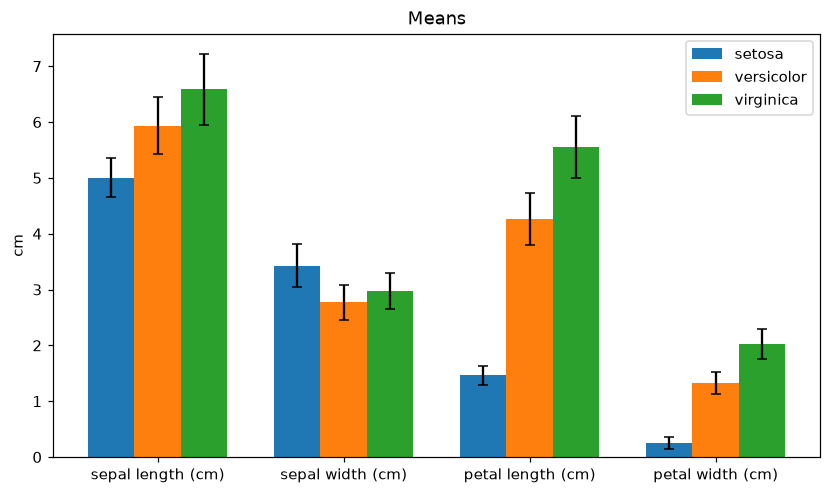

In [8]:
ax = plot_2()

_bars = [c for c in ax.containers if isinstance(c, BarContainer)]
_means = df.groupby("species")[FEATURES].mean()
_expected = sorted(tuple(np.round(_means.loc[s].values, 6)) for s in SPECIES)
_actual = sorted(tuple(np.round([b.get_height() for b in c], 6)) for c in _bars)
_xt = [t.get_text() for t in ax.get_xticklabels() if t.get_text()]

run_checks("График 2 — сгруппированные столбцы со средними", [
    ("3 группы столбцов (по видам)",    lambda: len(_bars) == 3),
    ("В каждой группе 4 столбца",       lambda: all(len(c) == 4 for c in _bars)),
    ("Высоты столбцов = средние по видам", lambda: _actual == _expected),
    ("У всех групп есть усы ошибок",    lambda: all(c.errorbar is not None for c in _bars)),
    ("Подписи X = названия признаков",  lambda: set(_xt) == set(FEATURES)),
    ("Легенда из 3 видов",              lambda: len(ax.get_legend().get_texts()) == 3),
    ("Подпись оси Y задана",            lambda: ax.get_ylabel().strip() != ""),
    ("Заголовок задан",                 lambda: ax.get_title().strip() != ""),
])

### График 3 — тепловая карта корреляций
Постройте heatmap матрицы корреляций 4 признаков через `ax.imshow` (шкала −1..1, `cmap` на выбор).
Аннотируйте каждую ячейку значением с 2 знаками, добавьте colorbar и подписи осей (названия признаков).
Функция возвращает `ax`.

In [13]:
def plot_3():
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    corr = np.corrcoef(df[FEATURES].values, rowvar=False)

    im = ax.imshow(corr, cmap = 'coolwarm', vmin=-1, vmax=1)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center')
    fig.colorbar(im, ax=ax)
    ax.set_title("Correlation Matrix")
    ax.set_xticks(np.arange(len(FEATURES)), FEATURES, rotation=45, ha='right')
    ax.set_yticks(np.arange(len(FEATURES)), FEATURES)
    return ax

График 3 — тепловая карта корреляций
  [PASS] Есть изображение (imshow)
  [PASS] Данные = матрица корреляций
  [PASS] Пределы шкалы -1..1
  [PASS] Colorbar добавлен
  [PASS] 16 аннотаций со значениями
  [PASS] Значения аннотаций = корреляции
  [PASS] Подписи X = признаки
  [PASS] Подписи Y = признаки
  [PASS] Заголовок задан
  -> 9/9 проверок пройдено


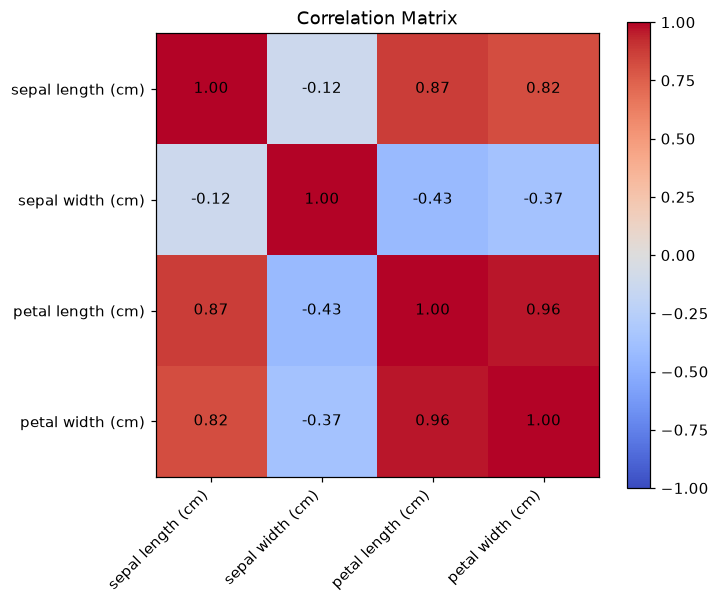

In [14]:
ax = plot_3()

_corr = np.corrcoef(df[FEATURES].values, rowvar=False)
_img = ax.images[0] if ax.images else None
_txt_vals = sorted(round(float(t.get_text()), 2) for t in ax.texts)
_expected_vals = sorted(round(float(v), 2) for v in _corr.ravel())
_xt = [t.get_text() for t in ax.get_xticklabels() if t.get_text()]
_yt = [t.get_text() for t in ax.get_yticklabels() if t.get_text()]

run_checks("График 3 — тепловая карта корреляций", [
    ("Есть изображение (imshow)",        lambda: _img is not None),
    ("Данные = матрица корреляций",      lambda: np.allclose(np.asarray(_img.get_array()), _corr)),
    ("Пределы шкалы -1..1",              lambda: np.allclose(_img.get_clim(), (-1, 1))),
    ("Colorbar добавлен",                lambda: _img.colorbar is not None),
    ("16 аннотаций со значениями",       lambda: len(ax.texts) == 16),
    ("Значения аннотаций = корреляции",  lambda: _txt_vals == _expected_vals),
    ("Подписи X = признаки",             lambda: set(_xt) == set(FEATURES)),
    ("Подписи Y = признаки",             lambda: set(_yt) == set(FEATURES)),
    ("Заголовок задан",                  lambda: ax.get_title().strip() != ""),
])

### График 4 — box plot с наложением точек
Для длины лепестка по видам постройте box plot с `patch_artist=True` и **разными цветами** коробок,
затем наложите джиттер-точки всех 150 наблюдений (небольшой случайный сдвиг по X).
Подписи оси X — виды. Функция возвращает `ax`.

In [20]:
def plot_4():
    fig, ax = plt.subplots(figsize=(7.5, 5))
    data = [df.loc[df['species'] == s, Y_COL].values for s in SPECIES]

    bp = ax.boxplot(data, patch_artist=True)

    for patch, color in zip(bp['boxes'], ['lightblue', 'lightgreen', 'lightcoral']):
        patch.set_facecolor(color)

    for i, s in enumerate(SPECIES):
        y = df.loc[df['species'] == s, Y_COL].values
        xj = np.random.normal(i + 1, 0.04, size=len(y))
        ax.scatter(xj, y, alpha=0.)

    ax.set_title("Petal Length")
    ax.set_xticks([1,2,3], SPECIES)
    ax.set_ylabel(Y_COL)
    
    return ax

График 4 — box plot + наложение точек
  [PASS] 3 коробки (patch_artist)
  [PASS] Коробки разного цвета
  [PASS] Границы коробок = квартили Q1..Q3
  [PASS] Наложены все 150 точек
  [PASS] Y точек = длина лепестка
  [PASS] Подписи X = виды
  [PASS] Подпись оси Y задана
  [PASS] Заголовок задан
  -> 8/8 проверок пройдено


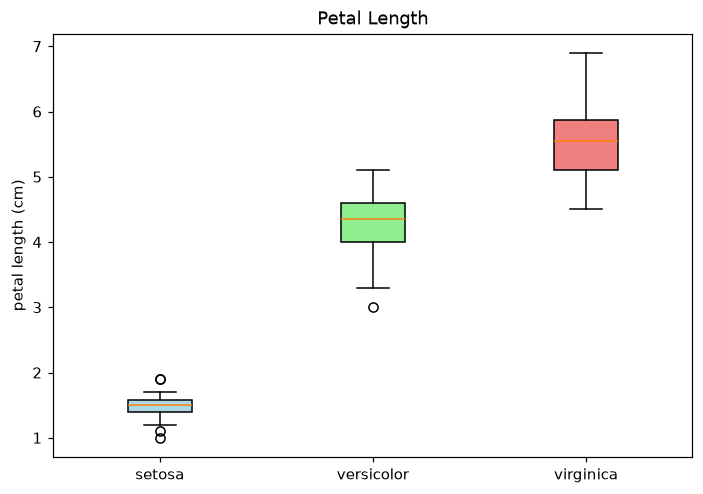

In [21]:
ax = plot_4()

_stats = {s: cbook.boxplot_stats(df.loc[df.species == s, Y_COL].values)[0] for s in SPECIES}
_expected_box = sorted((round(v["q1"], 6), round(v["q3"], 6)) for v in _stats.values())
_box_ranges = sorted(
    (round(float(p.get_path().vertices[:, 1].min()), 6),
     round(float(p.get_path().vertices[:, 1].max()), 6))
    for p in ax.patches
)
_xy = _all_offsets(ax)
_facecolors = {tuple(np.round(p.get_facecolor(), 3)) for p in ax.patches}
_xt = [t.get_text() for t in ax.get_xticklabels() if t.get_text()]

run_checks("График 4 — box plot + наложение точек", [
    ("3 коробки (patch_artist)",          lambda: len(ax.patches) == 3),
    ("Коробки разного цвета",             lambda: len(_facecolors) == 3),
    ("Границы коробок = квартили Q1..Q3", lambda: _box_ranges == _expected_box),
    ("Наложены все 150 точек",            lambda: _xy.shape[0] == 150),
    ("Y точек = длина лепестка",          lambda: np.allclose(np.sort(_xy[:, 1]), np.sort(df[Y_COL]))),
    ("Подписи X = виды",                  lambda: set(_xt) == set(SPECIES)),
    ("Подпись оси Y задана",              lambda: ax.get_ylabel().strip() != ""),
    ("Заголовок задан",                   lambda: ax.get_title().strip() != ""),
])

### График 5 — гистограмма и ECDF на двух осях
На основной оси — гистограмма длины лепестка (`bins=20`, частоты).
На второй оси (`ax1.twinx()`) — ECDF: `x = np.sort(значения)`, `y = np.arange(1, n+1)/n`.
Две подписи оси Y (слева/справа), подпись оси X, заголовок. Функция возвращает кортеж `(ax_hist, ax_ecdf)`.

In [24]:
def plot_5():
    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax2 = ax1.twinx()   # вторая ось Y с общей осью X

    petal_length = df[Y_COL].values

    ax1.hist(petal_length, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
    ax1.set_xlabel('Длина лепестка (Petal Length)')
    ax1.set_ylabel('Частота (Frequency)')

    sorted_data = np.sort(petal_length)
    n = len(sorted_data)
    ecdf = np.arange(1, n + 1) / n
    
    ax2.plot(sorted_data, ecdf, color='crimson', linewidth=2)
    ax2.set_ylabel('Накопленная доля (ECDF)')

    ax1.set_title('Гистограмма и ECDF для длины лепестка')
    return ax1, ax2

График 5 — гистограмма + ECDF на двух осях
  [PASS] Вторая ось — twin от первой (общий bbox)
  [PASS] Гистограмма из 20 столбцов
  [PASS] Сумма частот = 150
  [PASS] ECDF монотонно не убывает
  [PASS] ECDF заканчивается на 1.0
  [PASS] ECDF построена по длине лепестка
  [PASS] Левая подпись оси Y задана
  [PASS] Правая подпись оси Y задана
  [PASS] Подпись оси X задана
  -> 9/9 проверок пройдено


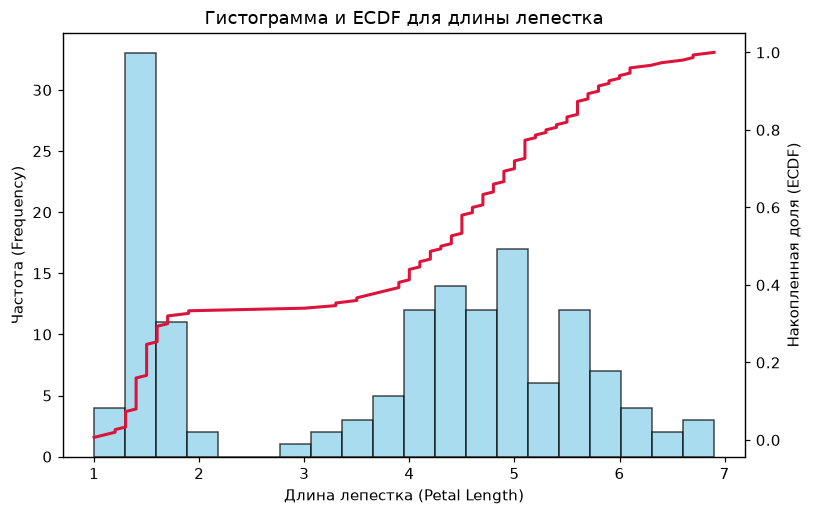

In [25]:
ax1, ax2 = plot_5()
_pl = df[Y_COL].values

def _ecdf_line():
    cand = sorted((l for l in ax2.lines if len(l.get_ydata()) >= 5), key=lambda l: len(l.get_ydata()))
    assert cand, "на второй оси нет линии ECDF"
    return cand[-1]

run_checks("График 5 — гистограмма + ECDF на двух осях", [
    ("Вторая ось — twin от первой (общий bbox)",
        lambda: np.allclose(ax1.get_position().bounds, ax2.get_position().bounds)),
    ("Гистограмма из 20 столбцов",       lambda: len(ax1.patches) == 20),
    ("Сумма частот = 150",               lambda: abs(sum(p.get_height() for p in ax1.patches) - 150) < 1e-6),
    ("ECDF монотонно не убывает",        lambda: bool(np.all(np.diff(_ecdf_line().get_ydata()) >= -1e-9))),
    ("ECDF заканчивается на 1.0",        lambda: abs(np.max(_ecdf_line().get_ydata()) - 1.0) < 1e-6),
    ("ECDF построена по длине лепестка", lambda: np.allclose(np.sort(_ecdf_line().get_xdata()), np.sort(_pl))),
    ("Левая подпись оси Y задана",       lambda: ax1.get_ylabel().strip() != ""),
    ("Правая подпись оси Y задана",      lambda: ax2.get_ylabel().strip() != ""),
    ("Подпись оси X задана",             lambda: ax1.get_xlabel().strip() != ""),
])